# Étape 5 — Retrieval dense avec les embeddings OpenAI

Ce notebook construit une baseline dense reproductible et la compare à BM25. Il calcule les embeddings des chunks et des requêtes avec `text-embedding-3-small`, les met dans un cache SQLite persistant, puis effectue une recherche cosine exacte avec NumPy.

Règles importantes :

- seuls `train` et `validation` sont chargés ; `test` reste verrouillé ;
- un texte déjà présent dans le cache ne déclenche pas un nouvel appel payant ;
- le coût estimé est affiché et contrôlé avant tout appel API ;
- cette étape évalue **Dense seul**. Qdrant, Hybrid et Reranking viendront après.


## 1. Dépendances et environnement


In [10]:
%pip install -q openai python-dotenv tiktoken numpy pandas matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
from __future__ import annotations

import hashlib
import json
import os
import platform
import sqlite3
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Iterator, Sequence

import matplotlib.pyplot as plt
import numpy as np
import openai
import pandas as pd
import tiktoken
from dotenv import load_dotenv
from IPython.display import display
from openai import APIConnectionError, APIStatusError, APITimeoutError, OpenAI, RateLimitError

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
DATASET_ROOT = PROJECT_ROOT / "data" / "processed" / "multidoc2dial_v1"
CONFIG_PATH = PROJECT_ROOT / "configs" / "dense_retrieval_experiments.json"

print(f"Project root : {PROJECT_ROOT}")
print(f"Configuration: {CONFIG_PATH}")
print(f"Python       : {platform.python_version()}")
print(f"NumPy/OpenAI : {np.__version__} / {openai.__version__}")


Project root : C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant
Configuration: C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant\configs\dense_retrieval_experiments.json
Python       : 3.12.7
NumPy/OpenAI : 1.26.4 / 2.8.1


## 2. Lecture, hash et écritures atomiques


In [12]:
def load_json(path: Path) -> dict[str, Any]:
    with path.open(encoding="utf-8") as handle:
        value = json.load(handle)
    if not isinstance(value, dict):
        raise TypeError(f"La racine de {path} doit être un objet JSON")
    return value


def iter_jsonl(path: Path) -> Iterator[dict[str, Any]]:
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            try:
                yield json.loads(line)
            except json.JSONDecodeError as error:
                raise ValueError(f"JSONL invalide : {path}, ligne {line_number}") from error


def load_jsonl(path: Path) -> list[dict[str, Any]]:
    return list(iter_jsonl(path))


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while block := handle.read(1024 * 1024):
            digest.update(block)
    return digest.hexdigest()


def text_sha256(text: str) -> str:
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def stable_hash(value: Any) -> str:
    payload = json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def write_json_atomic(path: Path, value: dict[str, Any] | list[Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    temporary.replace(path)


def write_jsonl_atomic(path: Path, records: Iterable[dict[str, Any]]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", encoding="utf-8", newline="\n") as handle:
        for record in records:
            handle.write(json.dumps(record, ensure_ascii=False, separators=(",", ":")))
            handle.write("\n")
    temporary.replace(path)


def write_npy_atomic(path: Path, matrix: np.ndarray) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.stem + ".tmp.npy")
    np.save(temporary, matrix, allow_pickle=False)
    temporary.replace(path)


def artifact_metadata(path: Path, records: int | None = None) -> dict[str, Any]:
    result = {"bytes": path.stat().st_size, "sha256": file_sha256(path)}
    if records is not None:
        result["records"] = records
    return result


def dataframe_records(frame: pd.DataFrame) -> list[dict[str, Any]]:
    return json.loads(frame.to_json(orient="records", double_precision=12))


## 3. Chargement strict du benchmark — le test n'est jamais ouvert


In [13]:
config = load_json(CONFIG_PATH)
config_hash = stable_hash(config)
benchmark_root = DATASET_ROOT / "retrieval_benchmarks" / config["benchmark_id"]
benchmark_manifest_path = benchmark_root / "manifest.json"
benchmark_manifest = load_json(benchmark_manifest_path)

assert benchmark_manifest["quality"]["status"] == "passed"
assert benchmark_manifest["status"] == "ready_for_retrieval_evaluation"
assert benchmark_manifest["benchmark_id"] == config["benchmark_id"]
development_splits = list(config["development_splits"])
locked_splits = set(config["locked_splits"])
assert not set(development_splits) & locked_splits
assert "test" in locked_splits and "test" not in development_splits

development_examples: list[dict[str, Any]] = []
benchmark_split_inputs: dict[str, dict[str, Any]] = {}
for split in development_splits:
    filename = f"{split}.jsonl"
    path = benchmark_root / filename
    expected = benchmark_manifest["outputs"][filename]
    assert file_sha256(path) == expected["sha256"]
    records = load_jsonl(path)
    assert len(records) == expected["records"]
    assert all(record["split"] == split for record in records)
    development_examples.extend(records)
    benchmark_split_inputs[split] = {"path": str(path.relative_to(PROJECT_ROOT)), **expected}
    print(f"{split:12s}: {len(records):>6,} exemples")

loaded_splits = {example["split"] for example in development_examples}
assert loaded_splits == set(development_splits)
assert not loaded_splits & locked_splits
assert len({example["id"] for example in development_examples}) == len(development_examples)

chunking_inputs = benchmark_manifest["inputs"]["strategies"]
assert set(config["strategies"]) == set(chunking_inputs)

bm25_report_path = (PROJECT_ROOT / "reports" / "generated" / "multidoc2dial_v1" /
                    "bm25_experiments" / config["bm25_experiment_id"] / "bm25_report.json")
bm25_report = load_json(bm25_report_path)
assert bm25_report["quality"]["status"] == "passed"
assert bm25_report["quality"]["test_evaluated"] is False
assert "test" in bm25_report["quality"]["locked_splits_not_loaded"]

experiment_fingerprint = stable_hash({
    "configuration": config,
    "benchmark_fingerprint": benchmark_manifest["benchmark_fingerprint"],
    "development_split_hashes": {split: value["sha256"] for split, value in benchmark_split_inputs.items()},
    "chunk_hashes": {name: value["sha256"] for name, value in chunking_inputs.items()},
    "bm25_report_sha256": file_sha256(bm25_report_path),
})
experiment_id = f"{config['experiment_name']}_{experiment_fingerprint[:10]}"
OUTPUT_ROOT = DATASET_ROOT / "dense_retrieval_experiments" / experiment_id
REPORT_ROOT = PROJECT_ROOT / "reports" / "generated" / "multidoc2dial_v1" / "dense_retrieval_experiments" / experiment_id

print(f"Développement : {len(development_examples):,} exemples")
print(f"Splits chargés : {sorted(loaded_splits)}")
print(f"Test verrouillé : {'test' not in loaded_splits}")
print(f"Experiment ID  : {experiment_id}")


train       : 24,603 exemples
validation  :  4,699 exemples
Développement : 29,302 exemples
Splits chargés : ['train', 'validation']
Test verrouillé : True
Experiment ID  : openai_dense_retrieval_v1_3b9e048ba8


## 4. Catalogue des textes à encoder

Un même texte peut apparaître dans plusieurs stratégies. Nous le hashons pour l'encoder une seule fois, tout en gardant les IDs de chunks propres à chaque stratégie. Le hash ne remplace pas le texte : il sert de clé stable du cache.


In [14]:
unique_texts: dict[str, str] = {}
chunk_catalogs: dict[str, list[dict[str, Any]]] = {}

def register_text(text: str) -> str:
    normalized = text.strip()
    if not normalized:
        raise ValueError("Texte vide impossible à encoder")
    text_hash = text_sha256(normalized)
    previous = unique_texts.setdefault(text_hash, normalized)
    if previous != normalized:
        raise RuntimeError("Collision SHA-256 détectée entre deux textes différents")
    return text_hash


for strategy in config["strategies"]:
    input_info = chunking_inputs[strategy]
    chunk_path = PROJECT_ROOT / input_info["artifact"]
    assert file_sha256(chunk_path) == input_info["sha256"]
    chunks = load_jsonl(chunk_path)
    assert len(chunks) == input_info["records"]
    assert len({chunk["id"] for chunk in chunks}) == len(chunks)
    catalog = []
    for chunk in chunks:
        text_hash = register_text(chunk["embedding_text"])
        catalog.append({
            "chunk_id": chunk["id"],
            "text_hash": text_hash,
            "source_span_ids": chunk["source_span_ids"],
            "domain": chunk["domain"],
            "document_id": chunk["document_id"],
            "parent_id": chunk["parent_id"],
        })
    chunk_catalogs[strategy] = catalog
    print(f"{strategy:24s}: {len(catalog):>5,} chunks")

query_hash_by_example: dict[str, str] = {}
query_text_by_hash: dict[str, str] = {}
for example in development_examples:
    query_hash = register_text(example["query"]["text"])
    query_hash_by_example[example["id"]] = query_hash
    query_text_by_hash[query_hash] = unique_texts[query_hash]

chunk_text_hashes = {item["text_hash"] for catalog in chunk_catalogs.values() for item in catalog}
query_text_hashes = set(query_text_by_hash)
print(f"Textes de chunks uniques   : {len(chunk_text_hashes):,}")
print(f"Requêtes uniques           : {len(query_text_hashes):,}")
print(f"Textes uniques à mettre en cache : {len(unique_texts):,}")


fixed_v1                : 2,370 chunks
structure_aware_v1      : 3,219 chunks
section_preserving_v1   : 1,273 chunks
hierarchical_v1         : 3,265 chunks
Textes de chunks uniques   : 8,044
Requêtes uniques           : 22,629
Textes uniques à mettre en cache : 30,673


## 5. Préflight tokens, cache SQLite et estimation du coût


In [15]:
embedding_config = config["embedding"]
model_name = embedding_config["model"]
requested_dimensions = embedding_config["dimensions"]
dimensions_key = "default" if requested_dimensions is None else str(requested_dimensions)
encoding = tiktoken.get_encoding(embedding_config["token_encoding"])
token_count_by_hash = {text_hash: len(encoding.encode(text)) for text_hash, text in unique_texts.items()}
too_long = {key: count for key, count in token_count_by_hash.items() if count > embedding_config["max_input_tokens"]}
assert not too_long, f"{len(too_long)} entrées dépassent la limite de tokens"
assert min(token_count_by_hash.values()) > 0

def embedding_cache_key(text_hash: str) -> str:
    return stable_hash({"model": model_name, "dimensions": dimensions_key, "text_sha256": text_hash})


class EmbeddingCache:
    def __init__(self, path: Path):
        path.parent.mkdir(parents=True, exist_ok=True)
        self.path = path
        self.connection = sqlite3.connect(path)
        self.connection.execute("PRAGMA journal_mode=WAL")
        self.connection.execute("PRAGMA synchronous=FULL")
        self.connection.execute(
            """CREATE TABLE IF NOT EXISTS embeddings (
                cache_key TEXT PRIMARY KEY, model TEXT NOT NULL, requested_dimensions TEXT NOT NULL,
                text_sha256 TEXT NOT NULL, vector_dim INTEGER NOT NULL, vector BLOB NOT NULL,
                estimated_token_count INTEGER NOT NULL, response_model TEXT NOT NULL, created_at_utc TEXT NOT NULL
            )"""
        )
        self.connection.commit()

    def existing_keys(self, keys: Sequence[str]) -> set[str]:
        found: set[str] = set()
        for start in range(0, len(keys), 800):
            batch = list(keys[start:start + 800])
            placeholders = ",".join("?" for _ in batch)
            query = f"SELECT cache_key FROM embeddings WHERE cache_key IN ({placeholders})"
            found.update(row[0] for row in self.connection.execute(query, batch))
        return found

    def get(self, text_hash: str) -> tuple[np.ndarray, str]:
        key = embedding_cache_key(text_hash)
        row = self.connection.execute(
            "SELECT model, requested_dimensions, text_sha256, vector_dim, vector, response_model "
            "FROM embeddings WHERE cache_key = ?", (key,),
        ).fetchone()
        if row is None:
            raise KeyError(text_hash)
        stored_model, stored_dimensions, stored_hash, vector_dim, blob, response_model = row
        assert stored_model == model_name and stored_dimensions == dimensions_key and stored_hash == text_hash
        vector = np.frombuffer(blob, dtype=np.float32).copy()
        if vector.size != vector_dim or not np.isfinite(vector).all() or np.linalg.norm(vector) == 0:
            raise ValueError(f"Vecteur en cache invalide : {text_hash}")
        return vector, response_model

    def put_many(self, records: list[dict[str, Any]]) -> None:
        now = datetime.now(timezone.utc).isoformat()
        rows = []
        for record in records:
            vector = np.asarray(record["vector"], dtype=np.float32)
            if vector.ndim != 1 or not np.isfinite(vector).all() or np.linalg.norm(vector) == 0:
                raise ValueError("L'API a renvoyé un embedding invalide")
            text_hash = record["text_hash"]
            rows.append((
                embedding_cache_key(text_hash), model_name, dimensions_key, text_hash, int(vector.size),
                sqlite3.Binary(vector.tobytes()), token_count_by_hash[text_hash], record["response_model"], now,
            ))
        self.connection.executemany(
            "INSERT OR REPLACE INTO embeddings VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)", rows,
        )
        self.connection.commit()

    def close(self) -> None:
        self.connection.execute("PRAGMA wal_checkpoint(TRUNCATE)")
        self.connection.close()


cache_path = DATASET_ROOT / "embedding_cache" / config["cache"]["sqlite_filename"]
cache = EmbeddingCache(cache_path)
all_text_hashes = sorted(unique_texts)
all_cache_keys = [embedding_cache_key(text_hash) for text_hash in all_text_hashes]
existing_cache_keys = cache.existing_keys(all_cache_keys)
missing_text_hashes = [text_hash for text_hash in all_text_hashes if embedding_cache_key(text_hash) not in existing_cache_keys]
missing_tokens = sum(token_count_by_hash[text_hash] for text_hash in missing_text_hashes)
estimated_new_cost_usd = missing_tokens / 1_000_000 * config["cost_guard"]["input_usd_per_million_tokens"]

print(f"Cache            : {cache_path.relative_to(PROJECT_ROOT)}")
print(f"Déjà en cache    : {len(existing_cache_keys):,}")
print(f"Textes manquants : {len(missing_text_hashes):,}")
print(f"Tokens estimés   : {missing_tokens:,}")
print(f"Coût maximum estimé de ce Run All : ${estimated_new_cost_usd:.6f}")
assert estimated_new_cost_usd <= config["cost_guard"]["maximum_estimated_new_cost_usd"], (
    "Le coût estimé dépasse le garde-fou configuré. Arrêt avant appel API."
)


Cache            : data\processed\multidoc2dial_v1\embedding_cache\openai_embeddings.sqlite3
Déjà en cache    : 0
Textes manquants : 30,673
Tokens estimés   : 2,588,414
Coût maximum estimé de ce Run All : $0.051768


## 6. Appels OpenAI reprenables

Crée un fichier `.env` à la racine en copiant `.env.example`, puis remplace la valeur. La clé n'est ni affichée ni enregistrée dans les artefacts. Si tous les textes sont déjà en cache, aucune clé n'est nécessaire.


In [16]:
def build_request_batches(text_hashes: list[str]) -> list[list[str]]:
    batches: list[list[str]] = []
    current: list[str] = []
    current_tokens = 0
    max_items = embedding_config["request_batch_size"]
    max_tokens = embedding_config["max_request_tokens"]
    for text_hash in text_hashes:
        token_count = token_count_by_hash[text_hash]
        if current and (len(current) >= max_items or current_tokens + token_count > max_tokens):
            batches.append(current)
            current, current_tokens = [], 0
        current.append(text_hash)
        current_tokens += token_count
    if current:
        batches.append(current)
    return batches


api_usage_records: list[dict[str, Any]] = []
request_batches = build_request_batches(missing_text_hashes)
if missing_text_hashes:
    load_dotenv(PROJECT_ROOT / embedding_config["dotenv_path"], override=False)
    api_key_name = embedding_config["api_key_environment_variable"]
    api_key = os.getenv(api_key_name)
    if not api_key or api_key == "replace_with_your_project_api_key":
        raise RuntimeError(
            f"{api_key_name} manque. Copie .env.example vers .env et ajoute ta clé, sans la mettre dans le notebook."
        )
    print(f"Clé API configurée : oui ({api_key_name}, valeur masquée)")
    client = OpenAI(api_key=api_key, timeout=embedding_config["request_timeout_seconds"], max_retries=0)

    for batch_number, batch_hashes in enumerate(request_batches, start=1):
        inputs = [unique_texts[text_hash] for text_hash in batch_hashes]
        request_kwargs: dict[str, Any] = {
            "model": model_name, "input": inputs,
            "encoding_format": embedding_config["encoding_format"],
        }
        if requested_dimensions is not None:
            request_kwargs["dimensions"] = requested_dimensions

        for attempt in range(embedding_config["max_retries"] + 1):
            started = time.perf_counter()
            try:
                response = client.embeddings.create(**request_kwargs)
                elapsed = time.perf_counter() - started
                ordered = sorted(response.data, key=lambda item: item.index)
                if len(ordered) != len(batch_hashes):
                    raise RuntimeError("Le nombre d'embeddings reçus ne correspond pas au batch envoyé")
                records = [
                    {"text_hash": text_hash, "vector": item.embedding, "response_model": response.model}
                    for text_hash, item in zip(batch_hashes, ordered)
                ]
                cache.put_many(records)
                api_usage_records.append({
                    "batch_number": batch_number, "inputs": len(batch_hashes),
                    "estimated_input_tokens": sum(token_count_by_hash[key] for key in batch_hashes),
                    "api_prompt_tokens": int(response.usage.prompt_tokens),
                    "api_total_tokens": int(response.usage.total_tokens),
                    "response_model": response.model, "elapsed_seconds": elapsed, "attempts": attempt + 1,
                })
                print(f"Batch {batch_number:>3}/{len(request_batches)} sauvegardé — {len(batch_hashes):>3} textes")
                break
            except (RateLimitError, APITimeoutError, APIConnectionError) as error:
                retryable = True
                caught_error = error
            except APIStatusError as error:
                retryable = error.status_code >= 500
                caught_error = error
            if not retryable or attempt >= embedding_config["max_retries"]:
                raise caught_error
            delay = min(
                embedding_config["maximum_backoff_seconds"],
                embedding_config["initial_backoff_seconds"] * (2 ** attempt),
            )
            print(f"Erreur temporaire ({type(caught_error).__name__}), nouvel essai dans {delay:.1f}s")
            time.sleep(delay)
else:
    print("Tous les embeddings sont déjà en cache : aucun appel OpenAI effectué.")

all_existing_after = cache.existing_keys(all_cache_keys)
assert len(all_existing_after) == len(all_cache_keys), "Le cache est incomplet après les appels API"
actual_api_tokens = sum(record["api_prompt_tokens"] for record in api_usage_records)
actual_new_cost_usd = actual_api_tokens / 1_000_000 * config["cost_guard"]["input_usd_per_million_tokens"]
print(f"Appels API de cette exécution : {len(api_usage_records)}")
print(f"Coût calculé de cette exécution : ${actual_new_cost_usd:.6f}")


Clé API configurée : oui (OPENAI_API_KEY, valeur masquée)
Batch   1/240 sauvegardé — 128 textes
Batch   2/240 sauvegardé — 128 textes
Batch   3/240 sauvegardé — 128 textes
Batch   4/240 sauvegardé — 128 textes
Batch   5/240 sauvegardé — 128 textes
Batch   6/240 sauvegardé — 128 textes
Batch   7/240 sauvegardé — 128 textes
Batch   8/240 sauvegardé — 128 textes
Batch   9/240 sauvegardé — 128 textes
Batch  10/240 sauvegardé — 128 textes
Batch  11/240 sauvegardé — 128 textes
Batch  12/240 sauvegardé — 128 textes
Batch  13/240 sauvegardé — 128 textes
Batch  14/240 sauvegardé — 128 textes
Batch  15/240 sauvegardé — 128 textes
Batch  16/240 sauvegardé — 128 textes
Batch  17/240 sauvegardé — 128 textes
Batch  18/240 sauvegardé — 128 textes
Batch  19/240 sauvegardé — 128 textes
Batch  20/240 sauvegardé — 128 textes
Batch  21/240 sauvegardé — 128 textes
Batch  22/240 sauvegardé — 128 textes
Batch  23/240 sauvegardé — 128 textes
Batch  24/240 sauvegardé — 128 textes
Batch  25/240 sauvegardé — 128

## 7. Construction des matrices normalisées


In [17]:
def normalized_matrix(text_hashes: Sequence[str]) -> tuple[np.ndarray, set[str]]:
    vectors, response_models = [], set()
    expected_dimension = None
    for text_hash in text_hashes:
        vector, response_model = cache.get(text_hash)
        if expected_dimension is None:
            expected_dimension = vector.size
        if vector.size != expected_dimension:
            raise ValueError("Dimensions incohérentes dans le cache")
        vector = vector / np.linalg.norm(vector)
        vectors.append(vector.astype(np.float32, copy=False))
        response_models.add(response_model)
    matrix = np.vstack(vectors).astype(np.float32, copy=False)
    assert np.allclose(np.linalg.norm(matrix, axis=1), 1.0, atol=1e-5)
    return matrix, response_models


query_hashes_ordered = sorted(query_text_hashes)
query_row_by_hash = {text_hash: row for row, text_hash in enumerate(query_hashes_ordered)}
query_matrix, response_models = normalized_matrix(query_hashes_ordered)
query_matrix_path = OUTPUT_ROOT / "vectors" / "query_vectors.npy"
query_index_path = OUTPUT_ROOT / "vectors" / "query_index.json"
write_npy_atomic(query_matrix_path, query_matrix)
write_json_atomic(query_index_path, {"text_hashes": query_hashes_ordered, "rows": len(query_hashes_ordered)})

chunk_matrices: dict[str, np.ndarray] = {}
chunk_ids_by_strategy: dict[str, np.ndarray] = {}
chunk_spans_by_strategy: dict[str, dict[str, frozenset[str]]] = {}
vector_artifacts: dict[str, dict[str, Any]] = {}
for strategy, catalog in chunk_catalogs.items():
    text_hashes = [item["text_hash"] for item in catalog]
    matrix, models = normalized_matrix(text_hashes)
    response_models.update(models)
    chunk_ids = np.asarray([item["chunk_id"] for item in catalog], dtype=str)
    chunk_matrices[strategy] = matrix
    chunk_ids_by_strategy[strategy] = chunk_ids
    chunk_spans_by_strategy[strategy] = {
        item["chunk_id"]: frozenset(item["source_span_ids"]) for item in catalog
    }
    strategy_root = OUTPUT_ROOT / "vectors" / strategy
    matrix_path = strategy_root / "chunk_vectors.npy"
    metadata_path = strategy_root / "chunk_index.json"
    write_npy_atomic(matrix_path, matrix)
    write_json_atomic(metadata_path, {
        "strategy": strategy, "rows": len(catalog), "dimension": matrix.shape[1],
        "chunks": catalog,
    })
    vector_artifacts[strategy] = {
        "chunk_vectors.npy": artifact_metadata(matrix_path, len(catalog)),
        "chunk_index.json": artifact_metadata(metadata_path, len(catalog)),
    }
    print(f"{strategy:24s}: matrice {matrix.shape}")

returned_dimension = int(query_matrix.shape[1])
if requested_dimensions is not None:
    assert returned_dimension == requested_dimensions
print(f"Dimension réellement renvoyée : {returned_dimension}")
print(f"Modèle(s) déclaré(s) par l'API/cache : {sorted(response_models)}")


fixed_v1                : matrice (2370, 1536)
structure_aware_v1      : matrice (3219, 1536)
section_preserving_v1   : matrice (1273, 1536)
hierarchical_v1         : matrice (3265, 1536)
Dimension réellement renvoyée : 1536
Modèle(s) déclaré(s) par l'API/cache : ['text-embedding-3-small']


## 8. Recherche cosine exacte et métriques


In [18]:
TOP_K_VALUES = sorted(config["evaluation"]["top_k_values"])
MAX_K = max(TOP_K_VALUES)

def rank_dense_row(scores: np.ndarray, chunk_ids: np.ndarray, max_k: int) -> list[tuple[str, float]]:
    if not np.isfinite(scores).all():
        raise ValueError("Score cosine non fini")
    if scores.size > max_k:
        top_positions = np.argpartition(scores, -max_k)[-max_k:]
        threshold = scores[top_positions].min()
        candidates = np.flatnonzero(scores >= threshold)
    else:
        candidates = np.arange(scores.size)
    order = np.lexsort((chunk_ids[candidates], -scores[candidates]))[:max_k]
    selected = candidates[order]
    return [(str(chunk_ids[position]), float(scores[position])) for position in selected]


def search_unique_queries(
    query_vectors: np.ndarray, chunk_vectors: np.ndarray, chunk_ids: np.ndarray,
    batch_size: int, max_k: int,
) -> tuple[list[list[tuple[str, float]]], dict[str, float]]:
    started = time.perf_counter()
    rankings = []
    for start in range(0, len(query_vectors), batch_size):
        scores = query_vectors[start:start + batch_size] @ chunk_vectors.T
        rankings.extend(rank_dense_row(row, chunk_ids, max_k) for row in scores)
    elapsed = time.perf_counter() - started
    return rankings, {
        "queries": len(query_vectors), "total_seconds": elapsed,
        "queries_per_second": len(query_vectors) / elapsed if elapsed else 0.0,
    }


def binary_ndcg(ranked_ids: list[str], relevant_ids: set[str], k: int) -> float:
    gains = [1.0 if chunk_id in relevant_ids else 0.0 for chunk_id in ranked_ids[:k]]
    dcg = sum(gain / np.log2(rank + 2.0) for rank, gain in enumerate(gains))
    ideal_relevant = min(len(relevant_ids), k)
    if ideal_relevant == 0:
        return 0.0
    ideal_dcg = sum(1.0 / np.log2(rank + 2.0) for rank in range(ideal_relevant))
    return float(dcg / ideal_dcg)


def score_rankings(
    examples: list[dict[str, Any]], rankings: list[list[tuple[str, float]]], strategy: str,
) -> pd.DataFrame:
    if len(examples) != len(rankings):
        raise ValueError("Le nombre de rankings ne correspond pas aux exemples")
    chunk_ids = set(chunk_ids_by_strategy[strategy].tolist())
    chunk_spans = chunk_spans_by_strategy[strategy]
    rows = []
    for example, ranking in zip(examples, rankings):
        ranked_ids = [chunk_id for chunk_id, _ in ranking]
        gold_spans = set(example["gold"]["span_ids"])
        relevant_ids = set(example["strategy_ground_truth"][strategy]["relevant_chunk_ids"])
        if not relevant_ids <= chunk_ids:
            raise ValueError(f"Ground truth inconnue : {example['id']} / {strategy}")
        first_rank = next((rank for rank, item in enumerate(ranked_ids[:MAX_K], 1) if item in relevant_ids), None)
        row = {
            "example_id": example["id"], "split": example["split"], "domain": example["domain"],
            "cohort": example["cohort"], "is_short_query": bool(example["query"]["is_short"]),
            "is_response_act": bool(example["query"]["is_response_act"]),
            "exact_text_overlap_free": bool(example["diagnostics"]["exact_text_overlap_free"]),
            "strategy": strategy, "run": "dense_openai_exact",
            "gold_span_count": len(gold_spans), "returned_chunks": len(ranked_ids),
            "zero_result": not ranked_ids, f"mrr@{MAX_K}": 1.0 / first_rank if first_rank else 0.0,
        }
        for k in TOP_K_VALUES:
            covered = set()
            for chunk_id in ranked_ids[:k]:
                covered.update(chunk_spans[chunk_id] & gold_spans)
            row[f"evidence_recall@{k}"] = len(covered) / len(gold_spans)
            row[f"any_evidence_hit@{k}"] = float(bool(covered))
            row[f"all_evidence_hit@{k}"] = float(covered == gold_spans)
            row[f"chunk_ndcg@{k}"] = binary_ndcg(ranked_ids, relevant_ids, k)
        rows.append(row)
    return pd.DataFrame(rows)


def slice_masks(frame: pd.DataFrame) -> dict[str, pd.Series]:
    primary = frame["cohort"] == config["evaluation"]["primary_cohort"]
    return {
        "all_examples": pd.Series(True, index=frame.index),
        "official_primary": primary,
        "overlap_free_primary": primary & frame["exact_text_overlap_free"],
        "short_query_primary": primary & frame["is_short_query"],
        "non_short_query_primary": primary & ~frame["is_short_query"],
        "agent_continuation": frame["cohort"] == "agent_continuation",
    }


METRIC_COLUMNS = [
    f"{name}@{k}" for k in TOP_K_VALUES
    for name in ("evidence_recall", "any_evidence_hit", "all_evidence_hit", "chunk_ndcg")
] + [f"mrr@{MAX_K}"]

def summarize_metrics(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for split in sorted(frame["split"].unique()):
        split_frame = frame[frame["split"] == split]
        for slice_name, mask in slice_masks(split_frame).items():
            subset = split_frame[mask]
            if subset.empty:
                continue
            row = {
                "strategy": subset["strategy"].iloc[0], "run": subset["run"].iloc[0],
                "split": split, "slice": slice_name, "queries": len(subset),
                "zero_result_rate": float(subset["zero_result"].mean()),
                "mean_returned_chunks": float(subset["returned_chunks"].mean()),
            }
            row.update({column: float(subset[column].mean()) for column in METRIC_COLUMNS})
            rows.append(row)
    return pd.DataFrame(rows)


def summarize_by_domain(frame: pd.DataFrame) -> pd.DataFrame:
    primary = frame[frame["cohort"] == config["evaluation"]["primary_cohort"]]
    columns = ["evidence_recall@1", "evidence_recall@5", "all_evidence_hit@5", f"mrr@{MAX_K}"]
    result = primary.groupby(["split", "domain"], as_index=False)[columns].mean()
    result.insert(0, "strategy", frame["strategy"].iloc[0])
    result.insert(1, "run", frame["run"].iloc[0])
    return result


In [19]:
metric_frames, summary_frames, domain_frames = [], [], []
performance_records, ranking_artifacts = [], {}
example_ranking_positions = [query_row_by_hash[query_hash_by_example[item["id"]]] for item in development_examples]

for strategy in config["strategies"]:
    unique_rankings, performance = search_unique_queries(
        query_matrix, chunk_matrices[strategy], chunk_ids_by_strategy[strategy],
        config["evaluation"]["query_batch_size"], MAX_K,
    )
    example_rankings = [unique_rankings[position] for position in example_ranking_positions]
    metric_frame = score_rankings(development_examples, example_rankings, strategy)
    metric_frames.append(metric_frame)
    summary_frames.append(summarize_metrics(metric_frame))
    domain_frames.append(summarize_by_domain(metric_frame))
    performance_records.append({"strategy": strategy, "measurement": "bulk_exact_cosine_unique_queries", **performance})

    if config["evaluation"]["persist_validation_rankings"]:
        ranking_path = OUTPUT_ROOT / "rankings" / strategy / "dense_validation.jsonl"
        def validation_records() -> Iterator[dict[str, Any]]:
            for example, ranking in zip(development_examples, example_rankings):
                if example["split"] == "validation":
                    yield {
                        "schema_version": "1.0.0", "experiment_id": experiment_id,
                        "example_id": example["id"], "split": "validation",
                        "cohort": example["cohort"], "strategy": strategy,
                        "run": "dense_openai_exact", "model": model_name,
                        "chunk_ids": [item[0] for item in ranking],
                        "scores": [item[1] for item in ranking],
                    }
        write_jsonl_atomic(ranking_path, validation_records())
        ranking_artifacts[strategy] = artifact_metadata(
            ranking_path, benchmark_manifest["outputs"]["validation.jsonl"]["records"],
        )
    print(f"{strategy:24s}: retrieval et métriques terminés")

metrics_frame = pd.concat(metric_frames, ignore_index=True)
summary_df = pd.concat(summary_frames, ignore_index=True)
domain_df = pd.concat(domain_frames, ignore_index=True)


fixed_v1                : retrieval et métriques terminés
structure_aware_v1      : retrieval et métriques terminés
section_preserving_v1   : retrieval et métriques terminés
hierarchical_v1         : retrieval et métriques terminés


## 9. Comparaison Dense vs BM25 sur validation


,strategy,queries,evidence_recall@1_dense,evidence_recall@5_dense,evidence_recall@10_dense,mrr@10_dense,evidence_recall@1_bm25,evidence_recall@5_bm25,evidence_recall@10_bm25,mrr@10_bm25,delta_evidence_recall@1,delta_evidence_recall@5,delta_evidence_recall@10,delta_mrr@10
0,fixed_v1,4427,0.2388,0.4368,0.5189,0.3265,0.2298,0.4281,0.5058,0.3166,0.0090,0.0087,0.0131,0.0099
1,section_preserving_v1,4427,0.2268,0.4333,0.5218,0.3167,0.2566,0.4637,0.5387,0.3476,-0.0298,-0.0305,-0.0169,-0.0309
2,structure_aware_v1,4427,0.2109,0.4188,0.4965,0.3049,0.2228,0.4322,0.4992,0.3158,-0.0119,-0.0135,-0.0027,-0.0108
3,hierarchical_v1,4427,0.2092,0.4174,0.4939,0.3023,0.2260,0.4325,0.4938,0.3156,-0.0168,-0.0151,0.0001,-0.0133


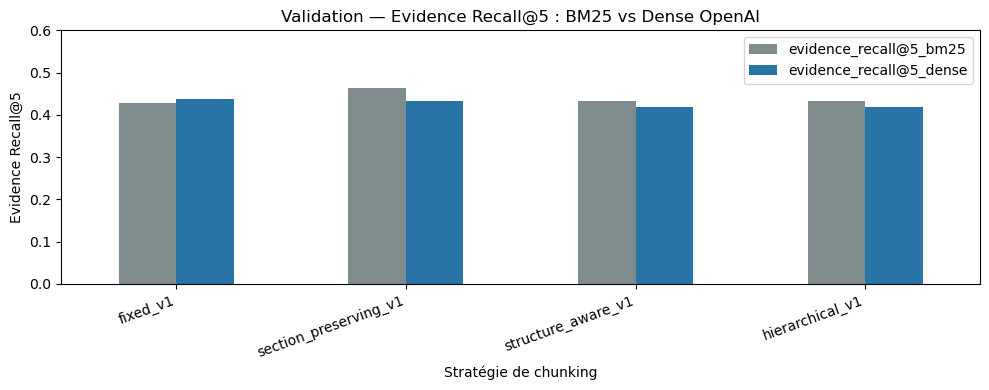

Meilleure stratégie Dense à Recall@5 : fixed_v1 (0.4368)


In [20]:
dense_validation = summary_df[(summary_df["split"] == "validation") & (summary_df["slice"] == "official_primary")].copy()
bm25_all_metrics = pd.DataFrame(bm25_report["metrics_summary"])
bm25_validation = bm25_all_metrics[(bm25_all_metrics["split"] == "validation") &
                                     (bm25_all_metrics["slice"] == "official_primary") &
                                     (bm25_all_metrics["run"] == "tuned_validation")].copy()
comparison = dense_validation[["strategy", "queries", "evidence_recall@1", "evidence_recall@5", "evidence_recall@10", f"mrr@{MAX_K}"]].merge(
    bm25_validation[["strategy", "evidence_recall@1", "evidence_recall@5", "evidence_recall@10", f"mrr@{MAX_K}"]],
    on="strategy", suffixes=("_dense", "_bm25"), validate="one_to_one",
)
for metric in ["evidence_recall@1", "evidence_recall@5", "evidence_recall@10", f"mrr@{MAX_K}"]:
    comparison[f"delta_{metric}"] = comparison[f"{metric}_dense"] - comparison[f"{metric}_bm25"]
comparison = comparison.sort_values("evidence_recall@5_dense", ascending=False).reset_index(drop=True)
display(comparison.round(4))

plot_frame = comparison.set_index("strategy")[["evidence_recall@5_bm25", "evidence_recall@5_dense"]]
ax = plot_frame.plot(kind="bar", figsize=(10, 4), color=["#7f8c8d", "#2874a6"])
ax.set_title("Validation — Evidence Recall@5 : BM25 vs Dense OpenAI")
ax.set_ylabel("Evidence Recall@5")
ax.set_xlabel("Stratégie de chunking")
ax.set_ylim(0, max(0.6, float(plot_frame.max().max()) + 0.05))
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best_dense = comparison.iloc[0]
print(f"Meilleure stratégie Dense à Recall@5 : {best_dense['strategy']} ({best_dense['evidence_recall@5_dense']:.4f})")


## 10. Latence locale et quality gates


In [21]:
rng = np.random.default_rng(config["performance"]["random_seed"])
sample_size = min(config["performance"]["latency_sample_size"], len(query_matrix))
sample_rows = rng.choice(len(query_matrix), size=sample_size, replace=False)
warmup = min(config["performance"]["latency_warmup_queries"], sample_size)
for strategy in config["strategies"]:
    matrix, ids = chunk_matrices[strategy], chunk_ids_by_strategy[strategy]
    for row in sample_rows[:warmup]:
        rank_dense_row(query_matrix[row] @ matrix.T, ids, MAX_K)
    latencies_ms = []
    for row in sample_rows:
        started = time.perf_counter()
        rank_dense_row(query_matrix[row] @ matrix.T, ids, MAX_K)
        latencies_ms.append((time.perf_counter() - started) * 1000)
    performance_records.append({
        "strategy": strategy, "measurement": "single_query_exact_cosine_compute_only",
        "queries": sample_size, "mean_ms": float(np.mean(latencies_ms)),
        "p50_ms": float(np.quantile(latencies_ms, 0.50)),
        "p95_ms": float(np.quantile(latencies_ms, 0.95)),
        "p99_ms": float(np.quantile(latencies_ms, 0.99)),
    })

performance_df = pd.DataFrame(performance_records)
display(performance_df[performance_df["measurement"] == "single_query_exact_cosine_compute_only"].round(3))

quality_errors = []
if "test" in loaded_splits:
    quality_errors.append("Le split test a été chargé")
if metrics_frame.empty or summary_df.empty:
    quality_errors.append("Les métriques sont vides")
if metrics_frame[METRIC_COLUMNS].isna().any().any():
    quality_errors.append("Certaines métriques sont NaN")
if not ((metrics_frame[METRIC_COLUMNS] >= 0) & (metrics_frame[METRIC_COLUMNS] <= 1)).all().all():
    quality_errors.append("Certaines métriques sortent de [0, 1]")
if set(metrics_frame["strategy"]) != set(config["strategies"]):
    quality_errors.append("Une stratégie manque dans les métriques")
if set(metrics_frame["split"]) != set(development_splits):
    quality_errors.append("Un split de développement manque")
if (metrics_frame["returned_chunks"] != MAX_K).any():
    quality_errors.append("Certaines requêtes n'ont pas exactement top-k résultats")
if actual_new_cost_usd > config["cost_guard"]["maximum_estimated_new_cost_usd"]:
    quality_errors.append("Coût réel supérieur au garde-fou")
for strategy, matrix in chunk_matrices.items():
    if matrix.shape != (len(chunk_catalogs[strategy]), returned_dimension):
        quality_errors.append(f"Matrice mal alignée : {strategy}")
    if not np.isfinite(matrix).all() or not np.allclose(np.linalg.norm(matrix, axis=1), 1, atol=1e-5):
        quality_errors.append(f"Vecteurs invalides ou non normalisés : {strategy}")

quality_status = "passed" if not quality_errors else "failed"
print(f"Quality gates : {quality_status}")
for error in quality_errors:
    print(f"- {error}")
assert not quality_errors, "Les quality gates Dense ont échoué"


,strategy,measurement,queries,total_seconds,queries_per_second,mean_ms,p50_ms,p95_ms,p99_ms
4,fixed_v1,single_query_exact_cosine_compute_only,500,NaN,NaN,0.254,0.216,0.454,0.567
5,structure_aware_v1,single_query_exact_cosine_compute_only,500,NaN,NaN,0.675,0.621,1.041,1.358
6,section_preserving_v1,single_query_exact_cosine_compute_only,500,NaN,NaN,0.143,0.138,0.175,0.225
7,hierarchical_v1,single_query_exact_cosine_compute_only,500,NaN,NaN,0.822,0.778,1.420,1.705


Quality gates : passed


## 11. Persistance du rapport et du manifeste


In [22]:
generated_at = datetime.now(timezone.utc).isoformat()
metrics_summary_path = REPORT_ROOT / "metrics_summary.json"
metrics_domain_path = REPORT_ROOT / "metrics_by_domain.json"
comparison_path = REPORT_ROOT / "dense_vs_bm25_validation.json"
performance_path = REPORT_ROOT / "performance.json"
api_usage_path = REPORT_ROOT / "api_usage.json"
write_json_atomic(metrics_summary_path, dataframe_records(summary_df))
write_json_atomic(metrics_domain_path, dataframe_records(domain_df))
write_json_atomic(comparison_path, dataframe_records(comparison))
write_json_atomic(performance_path, dataframe_records(performance_df))
write_json_atomic(api_usage_path, api_usage_records)

report_outputs = {
    "metrics_summary.json": artifact_metadata(metrics_summary_path, len(summary_df)),
    "metrics_by_domain.json": artifact_metadata(metrics_domain_path, len(domain_df)),
    "dense_vs_bm25_validation.json": artifact_metadata(comparison_path, len(comparison)),
    "performance.json": artifact_metadata(performance_path, len(performance_df)),
    "api_usage.json": artifact_metadata(api_usage_path, len(api_usage_records)),
}

manifest = {
    "schema_version": "1.0.0", "pipeline_stage": "dense_retrieval_evaluation",
    "generated_at_utc": generated_at, "experiment_id": experiment_id,
    "experiment_fingerprint": experiment_fingerprint,
    "implementation_version": config["implementation_version"],
    "configuration_path": str(CONFIG_PATH.relative_to(PROJECT_ROOT)), "configuration_hash": config_hash,
    "benchmark": {"benchmark_id": config["benchmark_id"], "manifest_sha256": file_sha256(benchmark_manifest_path),
                  "loaded_splits": sorted(loaded_splits), "locked_splits": sorted(locked_splits)},
    "bm25_baseline": {"experiment_id": config["bm25_experiment_id"], "report_sha256": file_sha256(bm25_report_path)},
    "embedding": {
        "provider": embedding_config["provider"], "requested_model": model_name,
        "response_models": sorted(response_models), "requested_dimensions": requested_dimensions,
        "returned_dimension": returned_dimension, "normalized_l2": True,
    },
    "cache": {
        "path": str(cache_path.relative_to(PROJECT_ROOT)), "required_entries": len(all_cache_keys),
        "hits_before_run": len(existing_cache_keys), "misses_before_run": len(missing_text_hashes),
        "complete_after_run": len(all_existing_after) == len(all_cache_keys),
    },
    "cost": {
        "pricing_as_of": config["cost_guard"]["pricing_as_of"],
        "pricing_source": config["cost_guard"]["pricing_source"],
        "usd_per_million_input_tokens": config["cost_guard"]["input_usd_per_million_tokens"],
        "estimated_new_tokens_before_run": missing_tokens,
        "estimated_new_cost_usd": estimated_new_cost_usd,
        "api_prompt_tokens_this_run": actual_api_tokens, "calculated_cost_usd_this_run": actual_new_cost_usd,
    },
    "vector_artifacts": {
        "queries": {"query_vectors.npy": artifact_metadata(query_matrix_path, len(query_hashes_ordered)),
                    "query_index.json": artifact_metadata(query_index_path, len(query_hashes_ordered))},
        "strategies": vector_artifacts,
    },
    "ranking_artifacts": ranking_artifacts, "report_outputs": report_outputs,
    "quality": {"status": quality_status, "errors": quality_errors, "test_split_loaded": False,
                "all_required_embeddings_cached": len(all_existing_after) == len(all_cache_keys)},
    "decision": "Dense baseline complete; chunking winner remains provisional until Hybrid and Reranking.",
}
manifest_path = OUTPUT_ROOT / "manifest.json"
write_json_atomic(manifest_path, manifest)
report = {**manifest, "validation_official_primary": dataframe_records(dense_validation),
          "dense_vs_bm25_validation": dataframe_records(comparison)}
report_path = REPORT_ROOT / "dense_report.json"
write_json_atomic(report_path, report)

cache.close()
print(f"Manifest : {manifest_path}")
print(f"Rapport  : {report_path}")


Manifest : C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant\data\processed\multidoc2dial_v1\dense_retrieval_experiments\openai_dense_retrieval_v1_3b9e048ba8\manifest.json
Rapport  : C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant\reports\generated\multidoc2dial_v1\dense_retrieval_experiments\openai_dense_retrieval_v1_3b9e048ba8\dense_report.json


## 12. Relecture indépendante des artefacts


In [23]:
persisted_manifest = load_json(manifest_path)
persisted_report = load_json(report_path)
assert persisted_manifest["experiment_fingerprint"] == experiment_fingerprint
assert persisted_report["quality"]["status"] == "passed"
assert persisted_report["quality"]["test_split_loaded"] is False
assert np.load(query_matrix_path, mmap_mode="r", allow_pickle=False).shape == query_matrix.shape
for strategy, catalog in chunk_catalogs.items():
    path = OUTPUT_ROOT / "vectors" / strategy / "chunk_vectors.npy"
    assert np.load(path, mmap_mode="r", allow_pickle=False).shape == (len(catalog), returned_dimension)
    ranking_path = OUTPUT_ROOT / "rankings" / strategy / "dense_validation.jsonl"
    assert sum(1 for _ in iter_jsonl(ranking_path)) == benchmark_manifest["outputs"]["validation.jsonl"]["records"]
for filename, metadata in report_outputs.items():
    assert file_sha256(REPORT_ROOT / filename) == metadata["sha256"]

print("✅ Relecture réussie")
print(f"✅ Quality gates : {persisted_report['quality']['status']}")
print("✅ Split test non chargé")
print("✅ Matrices, rankings, hashes et rapports cohérents")


✅ Relecture réussie
✅ Quality gates : passed
✅ Split test non chargé
✅ Matrices, rankings, hashes et rapports cohérents


## 13. Comment interpréter cette étape

Le tableau important est `Dense vs BM25 sur validation`. Une différence positive signifie que Dense retrouve mieux les spans de preuve ; une différence négative signifie que BM25 reste meilleur pour cette stratégie. Ne choisis pas encore définitivement le chunking : la prochaine expérience combinera les deux signaux avec un retrieval hybride.

La latence affichée mesure seulement le calcul cosine local avec un vecteur de requête déjà disponible. Elle n'inclut ni le réseau ni le temps de création d'un nouvel embedding par l'API.
